# 3장 · 임베딩 — 단어를 '의미 좌표'로 🧭

웹 챕터 **"임베딩"** 과 짝을 이루는 실습입니다.
웹 지도에서 점을 눌러 거리를 재봤다면, 여기서는 **좌표와 거리를 직접 계산**합니다.
(웹과 **같은 좌표·같은 결과**)

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터**: 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요. 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('ch3')

## 1. 단어 임베딩 (2D 목업)

각 단어에 2개의 숫자(좌표)를 붙였습니다. 네 무리(동물·과일·탈것·색)를 사분면에 나눠 배치했어요.
진짜 LLM 은 수백~수천 차원이지만, 눈으로 보려고 2차원으로 줄였습니다.

In [1]:
import numpy as np

EMB = {
    '고양이': (-3.0, 2.6), '강아지': (-3.3, 2.2), '호랑이': (-2.4, 3.0),   # 동물
    '사과':   ( 3.0, 2.6), '바나나': ( 3.4, 2.0), '포도':   ( 2.6, 3.0),   # 과일
    '자동차': (-3.0,-2.6), '버스':   (-3.4,-2.0), '기차':   (-2.5,-3.0),   # 탈것
    '빨강':   ( 3.0,-2.6), '파랑':   ( 3.4,-2.0), '노랑':   ( 2.5,-3.0),   # 색
}
print('고양이 의 임베딩 벡터:', EMB['고양이'])

고양이 의 임베딩 벡터: (-3.0, 2.6)


## 2. 거리로 '비슷함' 재기

두 단어가 비슷한지는 **좌표 사이 거리**로 잽니다(피타고라스). 작을수록 비슷.
$$\text{거리} = \sqrt{(x_1-x_2)^2 + (y_1-y_2)^2}$$

In [2]:
def dist(a, b):
    a, b = np.array(EMB[a]), np.array(EMB[b])
    return np.hypot(*(a - b))   # sqrt(dx^2 + dy^2)

print('고양이 ↔ 강아지 :', round(dist('고양이', '강아지'), 2), '(같은 무리 → 가까움)')
print('고양이 ↔ 자동차 :', round(dist('고양이', '자동차'), 2), '(다른 무리 → 멂)')

고양이 ↔ 강아지 : 0.5 (같은 무리 → 가까움)
고양이 ↔ 자동차 : 5.2 (다른 무리 → 멂)


## 3. '고양이'와 가장 비슷한 단어 찾기

모든 단어와의 거리를 재서 가까운 순으로 정렬합니다. (임베딩 검색·추천의 원리와 같아요)

In [3]:
def nearest(word, k=3):
    others = [(w, dist(word, w)) for w in EMB if w != word]
    others.sort(key=lambda x: x[1])
    return others[:k]

for w, d in nearest('고양이'):
    print(f'{w}: {d:.2f}')

강아지: 0.50
호랑이: 0.72
버스: 4.62


## 4. 단어 지도 그리기

웹에서 본 그 지도입니다. 같은 무리끼리 뭉쳐 있는 게 보이나요?

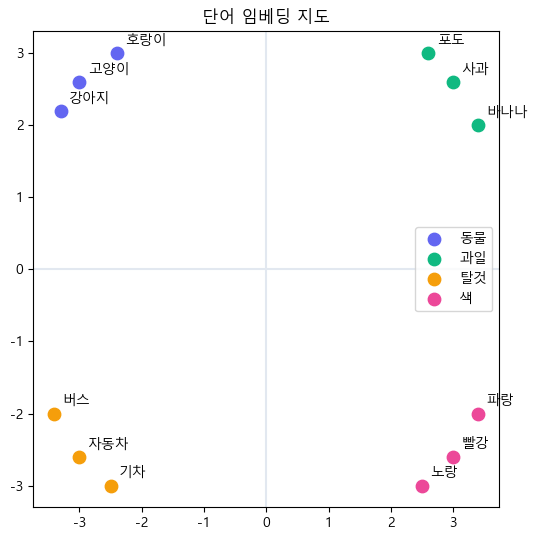

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows 한글 폰트
plt.rcParams['axes.unicode_minus'] = False

groups = {'동물': ['고양이','강아지','호랑이'], '과일': ['사과','바나나','포도'],
          '탈것': ['자동차','버스','기차'], '색': ['빨강','파랑','노랑']}
colors = {'동물':'#6366f1','과일':'#10b981','탈것':'#f59e0b','색':'#ec4899'}

plt.figure(figsize=(5.5, 5.5))
for g, words in groups.items():
    xs = [EMB[w][0] for w in words]; ys = [EMB[w][1] for w in words]
    plt.scatter(xs, ys, c=colors[g], label=g, s=80)
    for w in words:
        plt.annotate(w, EMB[w], textcoords='offset points', xytext=(6, 6))
plt.axhline(0, color='#e2e8f0'); plt.axvline(0, color='#e2e8f0')
plt.legend(); plt.title('단어 임베딩 지도'); plt.tight_layout(); plt.show()

## 5. 직접 해보기 ✏️

`'사과'` 와 가장 가까운 단어를 예상한 뒤 코드로 확인하세요. (같은 무리에서 나오겠죠?)

In [5]:
top = nearest('사과', k=1)[0]
print('사과와 가장 가까운 단어:', top[0], f'(거리 {top[1]:.2f})')

assert top[0] in ['바나나', '포도'], '같은 과일 무리에서 나와야 합니다!'
assert dist('사과','바나나') < dist('사과','자동차'), '같은 무리가 더 가까워야 합니다!'
print('✅ 뜻이 비슷한 단어가 좌표도 가깝습니다.')

사과와 가장 가까운 단어: 포도 (거리 0.57)
✅ 뜻이 비슷한 단어가 좌표도 가깝습니다.


---
이제 각 토큰이 **의미 좌표(벡터)** 를 가집니다. 하지만 아직 **순서 정보**가 없어요.
'개가 사람을 물다' 와 '사람이 개를 물다' 를 구분하려면 위치가 필요합니다.
다음 챕터(ch4 위치 인코딩)에서 순서를 더합니다. 🔢